# Лабораторная работа №3

## Градиентный спуск

### Задание

1. Сгенерировать датасет при помощи `sklearn.datasets.make_regression`, либо использовать набор данных из лабораторной работы по разведывательному анализу.
   - Признаков должно быть **не менее 2**, без учёта целевого признака (т.е. не менее 3 весов с учётом свободного члена);
   - при необходимости выполнить **масштабирование данных** (например, `StandardScaler`).

2. Самостоятельно реализовать функцию (пакетного, **не** стохастического) градиентного спуска по алгоритму:
   1. Инициализировать начальные веса ($w$) и скорость обучения ($varepsilon$) (learning rate);
   2. Организовать цикл по количеству итераций;
   3. Рассчитать новые веса по правилу градиентного шага:

      $$ w^{(k+1)} = w^{(k)} - \varepsilon \cdot \nabla Err\left(w^{(k)}\right) $$

      где для MSE градиент по весу ($w_j$) равен
      $$ \frac{\partial Err}{\partial w_j} = -\frac{2}{N} \sum_{i=1}^{N} x_{ij}\,\bigl(y_i - \hat{y}_i\bigr) $$

   4. Завершить цикл, если значение функции ошибки перестало существенно изменяться:
      $$ \bigl| Err\bigl(w^{(k+1)}\bigr) - Err\bigl(w^{(k)}\bigr) \bigr| < tol $$

3. Поэкспериментировать со **скоростью обучения** ($varepsilon$). Сделать выводы.

4. Модифицировать функцию: добавить выбор **случайного объекта** на каждой итерации, получив функцию **стохастического градиентного спуска (SGD)**.

5. Обучить линейную модель обоими способами:
   - градиентный спуск (GradDesc);
   - стохастический градиентный спуск (SGD).
   
   Нанести **среднеквадратичную ошибку (MSE)** обоих методов на один график. Сделать выводы о разнице скорости сходимости.

6. Реализовать регуляризацию:
   - для **чётных** вариантов — **L1** (lasso): $$Err_{L1} = MSE + \alpha \sum_j |w_j|$$
   - для **нечётных** вариантов — **L2** (ridge): $$ Err_{L2} = MSE + \alpha \sum_j w_j^2.$$

   **Для всех вариантов:** взять **20 коэффициентов регуляризации** ($alpha$) из широкого диапазона (например, от 0,001 до 1000, удобно — `np.logspace(-3, 3, 20)`) и показать на графике, как изменяются **веса** в зависимости от ($alpha$).

## Необходимые библиотеки

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

Для реализации грандиентного спуска был выбран датасет `fifa.csv`, использованный для реализации **второй лабораторной работы** в рамках **разведочного анализа данных**.

In [2]:
df = pd.read_csv('fifa.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     17955 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Skill Moves               18159 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  
 14  Contra

In [3]:
df.sample(10)

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,International Reputation,Skill Moves,Position,Joined,Contract Valid Until,Height,Weight,Release Clause
4283,175462,O. Vizcarrondo,34,Venezuela,71,71,ESTAC Troyes,725.0,6.0,Right,2.0,2.0,CB,2017,2019-01-01,6.250000,187.0,1300.0
5300,229019,A. Engin,21,Germany,70,82,MSV Duisburg,3200.0,4.0,Right,1.0,3.0,RM,2015,2021-01-01,5.916667,154.0,5700.0
5458,220362,K. Mahachi,24,Zimbabwe,70,73,Orlando Pirates,2300.0,1.0,Right,1.0,3.0,LW,2018,2021-01-01,5.583333,134.0,5000.0
18159,244561,L. Jagne,20,England,48,60,Morecambe,50.0,1.0,Left,1.0,2.0,CM,2018,2019-01-01,5.500000,137.0,98.0
17216,245435,R. Al Najjar,23,Saudi Arabia,55,62,Al Ittihad,90.0,3.0,Right,1.0,1.0,GK,2018,2021-01-01,6.166667,181.0,171.0
3980,186116,H. Lansbury,27,England,71,71,Aston Villa,2400.0,13.0,Right,1.0,3.0,CM,2017,2021-01-01,6.083333,187.0,4600.0
881,173546,J. Tomkins,29,England,78,79,Crystal Palace,9000.0,53.0,Right,2.0,2.0,RCB,2016,2021-01-01,6.333333,163.0,17800.0
2388,187033,S. Morrison,27,England,74,76,Cardiff City,5500.0,35.0,Right,1.0,2.0,RCB,2014,2022-01-01,6.333333,185.0,11400.0
14740,244767,Carlos Vicente,19,Spain,60,71,Real Zaragoza,350.0,1.0,Right,1.0,2.0,RW,2018,2019-01-01,5.750000,152.0,630.0
5567,163303,G. Whelan,34,Republic of Ireland,70,70,Aston Villa,550.0,10.0,Right,2.0,2.0,CDM,2017,2019-01-01,5.916667,176.0,1000.0


## Очистка исходных данных: дубликаты, пропуски, типы данных

Проверим датасет на **дубликаты**:

In [4]:
print(df.duplicated().sum())

0


Полные дубликаты отсутствуют. Проверим на дублирование **ID + имя игрока + возраст**:

In [5]:
print(df[["ID", "Name", "Age"]].duplicated().sum())

0


Дубликаты отсутствуют. Для надёжности проведём очистку от дубликатов и проверим датасет на правильность формирования.

In [6]:
df = df.drop_duplicates(["ID", "Name", "Age"]).reset_index(drop=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     17955 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Skill Moves               18159 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  
 14  Contra

Датасет не изменился. Проведём дальнейшую очистку датасета, заполнив пропуски **тем же путём, что и в предыдущей лабораторной работе**:
- Club пропущен у свободных агентов, поэтому заполняем меткой 'Free Agent'.
- Contract Valid Until содержит год в строке. Достаём его регуляркой и заполняем медианой.
- International Reputation и Skill Moves - порядковые признаки (1–5). Заполняем модой.
- Value сильно связан с Overall, поэтому заполняем медианой по группам Overall.

In [7]:
# Club: пропуск = игрок без клуба
df['Club'] = df['Club'].fillna('Free Agent')

# Contract Valid Until: оставляем только год, затем заполняем медианой
df['Contract Valid Until'] = pd.to_numeric(
    df['Contract Valid Until'].astype(str).str.extract(r'(\d{4})')[0])
df['Contract Valid Until'] = df['Contract Valid Until'].fillna(df['Contract Valid Until'].median())

# Value: медиана среди игроков с тем же Overall (стоимость зависит от рейтинга)
df['Value'] = df['Value'].fillna(df.groupby('Overall')['Value'].transform('median'))
df['Value'] = df['Value'].fillna(df['Value'].median())   # если для какого-то Overall медианы нет

# Дискретные признаки 1-5: заполняем модой
for col in ['International Reputation', 'Skill Moves']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      18207 non-null  object 
 7   Value                     18207 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18207 non-null  float64
 11  Skill Moves               18207 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  
 14  Contra

Замечаем, что всего 5 признаков **категориальные**: `Name`, `Nationality`, `Club`, `Preferred Foot`, `Position`. Остальные являются **числовыми**. 

Отмечу, что колонки `Preferred Foot`, `Position` можно закодировать с помощью **One-hot Encoding**, предварительно сгруппировав все позиции по линиям:
- защиты,
- полузащиты,
- атаки.

Очистим датафрейм от служебных колонок и не используемых в дальнейшем колонок:
- `ID`, `Name`;
- `Nationality`;
- `Club`.

In [9]:
pos_map = {
    'GK': 'GK',
    'CB': 'DEF', 'LCB': 'DEF', 'RCB': 'DEF', 'LB': 'DEF', 'RB': 'DEF', 'LWB': 'DEF', 'RWB': 'DEF',
    'CM': 'MID', 'LCM': 'MID', 'RCM': 'MID', 'CDM': 'MID', 'LDM': 'MID', 'RDM': 'MID',
    'CAM': 'MID', 'LAM': 'MID', 'RAM': 'MID', 'LM': 'MID', 'RM': 'MID',
    'ST': 'FWD', 'LS': 'FWD', 'RS': 'FWD', 'CF': 'FWD', 'LF': 'FWD', 'RF': 'FWD',
    'LW': 'FWD', 'RW': 'FWD'
}
df['Position_Group'] = df['Position'].map(pos_map).fillna('Other')

df = pd.get_dummies(df, columns=['Position_Group', 'Preferred Foot'],
                    prefix=['Pos', 'Foot'], dtype=int, drop_first=True)

money = ['Value', 'Wage', 'Release Clause']
for col in money:
    df[col] = np.log1p(df[col])
    
df = df.drop(columns=["ID", "Name", "Nationality", "Club", "Position"])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       18207 non-null  int64  
 1   Overall                   18207 non-null  int64  
 2   Potential                 18207 non-null  int64  
 3   Value                     18207 non-null  float64
 4   Wage                      18207 non-null  float64
 5   International Reputation  18207 non-null  float64
 6   Skill Moves               18207 non-null  float64
 7   Joined                    18207 non-null  int64  
 8   Contract Valid Until      18207 non-null  float64
 9   Height                    18207 non-null  float64
 10  Weight                    18207 non-null  float64
 11  Release Clause            18207 non-null  float64
 12  Pos_FWD                   18207 non-null  int64  
 13  Pos_GK                    18207 non-null  int64  
 14  Pos_MI

В качестве целевой переменной (таргета) была выбрана `Overall` - общий рейтинг игрока.

Поделим выборку на две части (тестовую и обучающую) для тестирования и обучения моделей градиентных спусков, а также стандартизируем признаки:

In [10]:
X = df.drop(columns=['Overall'])   # признаки
y = df['Overall']                  # таргет

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
scale_cols = [
    'Age', 'Potential', 'Value', 'Wage',
    'International Reputation', 'Skill Moves',
    'Joined', 'Contract Valid Until',
    'Height', 'Weight', 'Release Clause'
]

scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])  # fit только на train
X_test[scale_cols] = scaler.transform(X_test[scale_cols])        # тест масштабируем параметрами train

In [12]:
X_test

,Age,Potential,Value,Wage,International Reputation,Skill Moves,Joined,Contract Valid Until,Height,Weight,Release Clause,Pos_FWD,Pos_GK,Pos_MID,Foot_Right
5848,-0.236641,0.923800,0.265160,0.509274,-0.290747,-1.800683,-0.709639,-0.114898,0.616537,0.643510,0.266863,0,1,0,1
14634,0.404880,-1.672999,-0.793194,-0.566181,-0.290747,-0.478960,0.285488,-0.891097,0.239528,0.515201,-0.950819,1,0,0,1
11807,0.404880,-0.536899,-0.514641,-0.284563,-0.290747,-1.800683,0.285488,-0.114898,0.239528,0.835974,-0.641298,0,1,0,0
5826,1.046402,-0.374599,-0.045323,1.240738,-0.290747,-0.478960,0.285488,-0.891097,1.747563,1.541675,-0.033013,0,0,0,1
1989,-0.236641,1.410700,1.697005,1.509390,-0.290747,0.842763,0.783052,-0.114898,-0.891498,-0.062191,1.666545,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15966,-0.664322,-0.861499,-1.163361,-0.963100,-0.290747,-0.478960,0.285488,-0.891097,-0.137480,-0.062191,-1.189426,0,0,0,1
1604,1.046402,0.599200,1.250208,1.338712,-0.290747,0.842763,-1.704766,-0.891097,-0.514489,0.130273,1.305231,0,0,0,0
11712,1.687923,-1.186099,-0.767435,-0.566181,-0.290747,-0.478960,-0.709639,-0.891097,-0.514489,-0.062191,-0.925353,1,0,0,1
11716,0.404880,-1.186099,-0.560402,0.263257,-0.290747,-0.478960,0.783052,-0.891097,0.239528,0.130273,-0.653642,0,0,0,1


Данные стандартизированы, можно реализовывать функцию градиентного спуска.

In [13]:
def compute_gradient(X, y, w, b, l2_lambda=0.0):
    N = len(y)
    resid = y - (X @ w + b)
    grad_w = -2 / N * (X.T @ resid) + 2 * l2_lambda * w
    grad_b = -2 / N * resid.sum()
    return grad_w, grad_b


def gradient_descent(X, y, stochastic=False, learning_rate=0.01, n_iter=1000,
                     l2_lambda=0.0, batch_size=1, eps=1e-6,
                     w_init=None, b_init=0.0, random_state=42):
    """
    learning_rate: число (eta_k = const) или функция eta_k = learning_rate(k), k = 1, 2, ...
    Итерация: для GD один шаг по всей выборке, для SGD один проход по выборке (эпоха).
    Остановка: ||(w_k, b_k) - (w_{k-1}, b_{k-1})|| < eps; eps=None отключает проверку.
    Возвращает w, b и историю loss (MSE + l2*||w||^2); history[0] соответствует k=0.
    """
    X = np.asarray(X, float)
    y = np.asarray(y, float).ravel()
    n, m = X.shape
    rng = np.random.default_rng(random_state)

    w = np.zeros(m) if w_init is None else np.array(w_init, float)   # копия
    b = float(b_init)
    def loss():
        return np.mean((y - (X @ w + b)) ** 2) + l2_lambda * np.sum(w ** 2)

    history = [loss()]
    for k in range(1, n_iter + 1):
        eta = learning_rate
        w_prev, b_prev = w.copy(), b

        if stochastic:
            idx = rng.permutation(n)
            for s in range(0, n, batch_size):
                j = idx[s:s + batch_size]
                gw, gb = compute_gradient(X[j], y[j], w, b, l2_lambda)
                w -= eta * gw
                b -= eta * gb
        else:
            gw, gb = compute_gradient(X, y, w, b, l2_lambda)
            w -= eta * gw
            b -= eta * gb

        history.append(loss())

        if eps is not None:
            delta = np.sqrt(np.sum((w - w_prev) ** 2) + (b - b_prev) ** 2)
            if delta < eps:
                break
    return w, b, history

In [14]:
Xtr, Xte = X_train.to_numpy(), X_test.to_numpy()
y_mean = y_train.mean()
ytr = y_train.to_numpy() - y_mean

w_gd, b_gd, h_gd = gradient_descent(Xtr, ytr, stochastic=False,
                                    learning_rate=0.05, n_iter=200, l2_lambda=0.01)
w_sgd, b_sgd, h_sgd = gradient_descent(Xtr, ytr, stochastic=True,
                                       learning_rate=0.005, n_iter=20, l2_lambda=0.01,
                                       batch_size=32)

## Обучение моделей и эксперименты

Ячейка выше обучает пробные модели (GD и SGD с мини-батчем, $\lambda = 0.01$) на **стандартизированных** признаках и **центрированном** таргете (`ytr = y_train − mean`). Ниже — эксперименты по пунктам задания. Везде, где важна чистая MSE, используется `l2_lambda=0`, чтобы `history` содержала именно MSE, а не MSE + штраф.

Вспомогательная ячейка: RMSE на тесте считается в исходных пунктах рейтинга (к предсказанию возвращается среднее таргета по train).

In [15]:
import time

yte = y_test.to_numpy()

def test_rmse(w, b):
    """RMSE на тесте в пунктах рейтинга (к предсказанию возвращаем среднее таргета по train)."""
    return np.sqrt(np.mean((Xte @ w + b + y_mean - yte) ** 2))

print(f"Обучающая выборка: {Xtr.shape}, тестовая: {Xte.shape}")
print(f"RMSE константной модели (среднее по train): {np.sqrt(np.mean((yte - y_mean) ** 2)):.3f}")

Обучающая выборка: (14565, 15), тестовая: (3642, 15)
RMSE константной модели (среднее по train): 6.820


### Эксперимент со скоростью обучения (пункт 3)

Запускаем пакетный градиентный спуск при разных $\varepsilon$ (300 итераций, критерий остановки отключён, чтобы кривые были одной длины). Для квадратичной функции потерь $\frac{1}{N}\|y - Xw\|^2$ спуск устойчив при $\varepsilon < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное значение матрицы $\frac{2}{N}X^\top X$. Это значение посчитано в ячейке и добавлено в сравнение: 0.24 — чуть ниже порога, 0.26 — чуть выше.

Теоретический порог устойчивости GD: 2/λmax = 0.248


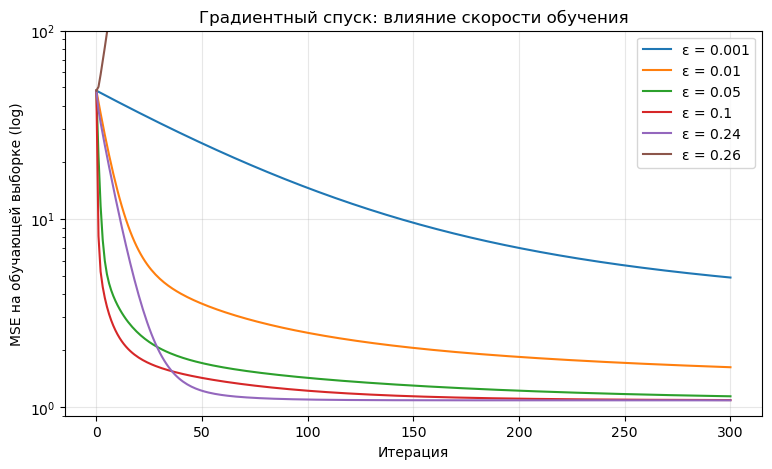

,ε,MSE (итер. 10),MSE (итер. 300),итераций до MSE<1.2,RMSE на тесте
0,0.001000,42,4.881,nan,2.18
1,0.010000,14.1,1.629,nan,1.22
2,0.050000,3.48,1.142,220.000000,1.04
3,0.100000,2.43,1.09,110.000000,1.02
4,0.240000,11.5,1.086,53.000000,1.02
5,0.260000,238,1.845e+25,nan,4.18e+12


In [16]:
# Здесь и далее l2_lambda=0, поэтому history = чистая MSE
lam_max = np.linalg.eigvalsh(2 * Xtr.T @ Xtr / len(Xtr)).max()
print(f"Теоретический порог устойчивости GD: 2/λmax = {2 / lam_max:.3f}")

lr_list = [0.001, 0.01, 0.05, 0.1, 0.24, 0.26]
rows = []
fig, ax = plt.subplots(figsize=(9, 5))
for lr in lr_list:
    with np.errstate(all='ignore'):
        w_, b_, h_ = gradient_descent(Xtr, ytr, learning_rate=lr, n_iter=300, eps=None)
    h_ = np.array(h_)
    ax.plot(h_, label=f"ε = {lr}")
    below = np.where(h_ < 1.2)[0]
    rows.append({
        'ε': lr,
        'MSE (итер. 10)': h_[10],
        'MSE (итер. 300)': h_[-1],
        'итераций до MSE<1.2': int(below[0]) if len(below) else None,
        'RMSE на тесте': test_rmse(w_, b_),
    })

ax.set_yscale('log')
ax.set_ylim(0.9, 100)
ax.set_xlabel('Итерация')
ax.set_ylabel('MSE на обучающей выборке (log)')
ax.set_title('Градиентный спуск: влияние скорости обучения')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame(rows).style.format({'MSE (итер. 10)': '{:.3g}', 'MSE (итер. 300)': '{:.4g}', 'RMSE на тесте': '{:.3g}'})

**Выводы по скорости обучения**

- Порог устойчивости $2/\lambda_{\max} \approx 0.248$. При $\varepsilon = 0.26$ (выше порога) спуск **расходится**: MSE растёт до $\sim 10^{25}$.
- Слишком малая скорость сходится медленно: при $\varepsilon = 0.001$ за 300 итераций MSE только 4.88 (RMSE на тесте 2.18), при $\varepsilon = 0.01$ — 1.63 (RMSE 1.22). Эти модели просто не успели обучиться.
- Умеренные значения $\varepsilon = 0.05 \ldots 0.1$ дают плавное монотонное убывание. При $\varepsilon = 0.1$ MSE опускается ниже 1.2 за 110 итераций (при $\varepsilon = 0.05$ — за 220), итоговая MSE 1.09, RMSE на тесте 1.02.
- Значение у границы ($\varepsilon = 0.24$) формально быстрее (53 итерации до MSE < 1.2), но кривая колеблется: на 10-й итерации MSE равна 11.5 против 2.43 при $\varepsilon = 0.1$. Так выбирать скорость рискованно: небольшое изменение данных или масштаба признаков может перевести спуск через порог.
- Практическое правило: брать $\varepsilon$ в 2–3 раза ниже порога $2/\lambda_{\max}$ либо подбирать по графику — ориентироваться на самую большую скорость, при которой кривая ещё убывает монотонно. Масштабирование признаков здесь критично: оно делает $\lambda_{\max}$ небольшим, и скорость порядка $0.1$ вообще допустима.

### GD и SGD: сравнение скорости сходимости (пункты 4–5)

В функции `gradient_descent` флаг `stochastic=True` превращает пакетный спуск в стохастический: на каждой итерации объекты перебираются в случайном порядке (`rng.permutation`), и вес обновляется после **каждого** объекта (при `batch_size=1`) или после мини-батча. Итерация SGD — это один проход по обучающей выборке, поэтому за итерацию SGD делает 14 565 обновлений весов (при `batch_size=1`), а GD — одно.

На графике MSE показана по двум осям: по числу итераций и по времени (итерация × среднее время одной итерации).

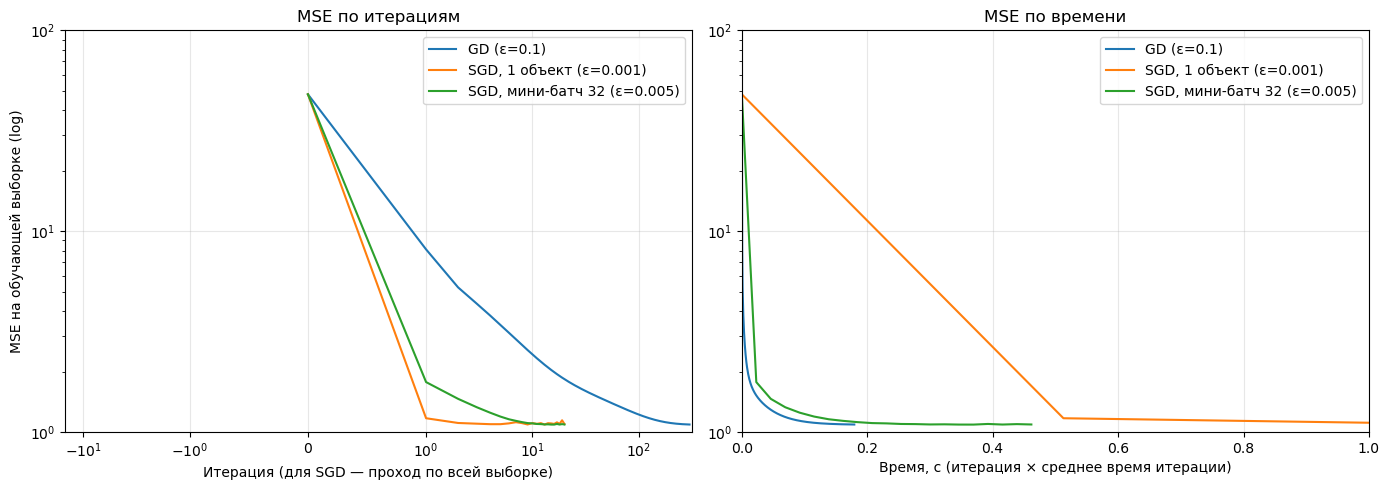

,метод,обновлений весов за итерацию,итераций до MSE<1.2,итераций до MSE<1.1,итоговая MSE,"время, с",RMSE на тесте
0,GD (ε=0.1),1,110,228,1.0901,0.18,1.0234
1,"SGD, 1 объект (ε=0.001)",14565,1,4,1.0965,10.26,1.0273
2,"SGD, мини-батч 32 (ε=0.005)",456,5,11,1.0906,0.46,1.0244


In [17]:
runs = {
    'GD (ε=0.1)':                dict(stochastic=False, learning_rate=0.1,   n_iter=300),
    'SGD, 1 объект (ε=0.001)':   dict(stochastic=True,  learning_rate=0.001, n_iter=20, batch_size=1),
    'SGD, мини-батч 32 (ε=0.005)': dict(stochastic=True, learning_rate=0.005, n_iter=20, batch_size=32),
}

res = {}
for name, kw in runs.items():
    t0 = time.perf_counter()
    w_, b_, h_ = gradient_descent(Xtr, ytr, eps=None, l2_lambda=0.0, **kw)
    elapsed = time.perf_counter() - t0
    res[name] = dict(w=w_, b=b_, h=np.array(h_), t_iter=elapsed / kw['n_iter'], elapsed=elapsed,
                     updates=1 if not kw['stochastic'] else int(np.ceil(len(ytr) / kw['batch_size'])))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, r in res.items():
    k = np.arange(len(r['h']))
    axes[0].plot(k, r['h'], label=name)
    axes[1].plot(k * r['t_iter'], r['h'], label=name)
for a in axes:
    a.set_yscale('log'); a.set_ylim(1.0, 100); a.grid(alpha=0.3); a.legend()
axes[0].set_xscale('symlog', linthresh=1)
axes[0].set_xlabel('Итерация (для SGD — проход по всей выборке)')
axes[0].set_ylabel('MSE на обучающей выборке (log)')
axes[0].set_title('MSE по итерациям')
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Время, с (итерация × среднее время итерации)')
axes[1].set_title('MSE по времени')
plt.tight_layout()
plt.show()

rows = []
for name, r in res.items():
    h_ = r['h']
    def first(thr):
        idx = np.where(h_ < thr)[0]
        return int(idx[0]) if len(idx) else None
    rows.append({'метод': name, 'обновлений весов за итерацию': r['updates'],
                 'итераций до MSE<1.2': first(1.2), 'итераций до MSE<1.1': first(1.1),
                 'итоговая MSE': h_[-1], 'время, с': r['elapsed'],
                 'RMSE на тесте': test_rmse(r['w'], r['b'])})
pd.DataFrame(rows).style.format({'итоговая MSE': '{:.4f}', 'время, с': '{:.2f}', 'RMSE на тесте': '{:.4f}'})

**Выводы о разнице скорости сходимости**

- **По итерациям SGD намного быстрее.** SGD с одним объектом опускает MSE ниже 1.2 уже на 1-й итерации и ниже 1.1 на 4-й; мини-батч 32 — на 5-й и 11-й; пакетному GD требуется 110 и 228 итераций. Причина — число обновлений весов за итерацию: 14 565 у SGD, 456 у мини-батча и 1 у GD.
- **SGD не сходится к точке, а колеблется около неё.** Градиент по одному объекту — шумная оценка, поэтому итоговая MSE у SGD (1.0965) чуть выше, чем у GD (1.0901), и кривая в конце «дрожит» (например, 1.099 → 1.144 → 1.097 на последних итерациях). При большей скорости колебания сильнее: в пробном запуске с $\varepsilon = 0.01$ MSE SGD с одним объектом гуляла в диапазоне примерно 1.1–1.5. Поэтому для SGD скорость берут заметно меньше, чем для GD (здесь 0.001 против 0.1), либо уменьшают её по ходу обучения (функция принимает `learning_rate` как функцию номера итерации).
- **По времени картина обратная.** В нашем случае данных немного (14 565 × 15), а GD вычисляется векторизованно: 300 итераций заняли около 0.05 с. SGD с `batch_size=1` — цикл Python по каждому объекту: 20 итераций заняли около 3 с, то есть до MSE < 1.1 SGD доходит примерно за 0.6 с против примерно 0.04 с у GD. Мини-батч 32 — разумный компромисс: 20 итераций за 0.11 с и сходимость по итерациям почти как у SGD. Преимущество SGD по времени проявляется на больших выборках, когда один полный проход по данным для GD дорог.
- **Качество на тесте одинаковое:** RMSE 1.023 (GD), 1.027 (SGD, 1 объект), 1.024 (SGD, мини-батч 32); для сравнения, константная модель даёт 6.82.

### L2-регуляризация и веса (пункт 6)

Реализован вариант для **нечётных** номеров — L2 (ridge): $Err_{L2} = MSE + \alpha \sum_j w_j^2$; в коде это параметр `l2_lambda`, градиент штрафа $2\alpha w$ уже учтён в `compute_gradient`. Свободный член $b$ не штрафуется.

Берём 20 значений $\alpha$ от $10^{-3}$ до $10^{3}$ (`np.logspace(-3, 3, 20)`) и для каждого обучаем модель градиентным спуском. Скорость обучения подбирается отдельно под каждое $\alpha$: $\varepsilon = 1/(\lambda_{\max} + 2\alpha)$ — иначе при больших $\alpha$ шаг превысит порог устойчивости и спуск разойдётся. Для проверки результат сравнивается с аналитическим решением гребневой регрессии.

Макс. отклонение весов GD от аналитического решения: 6.73e-09


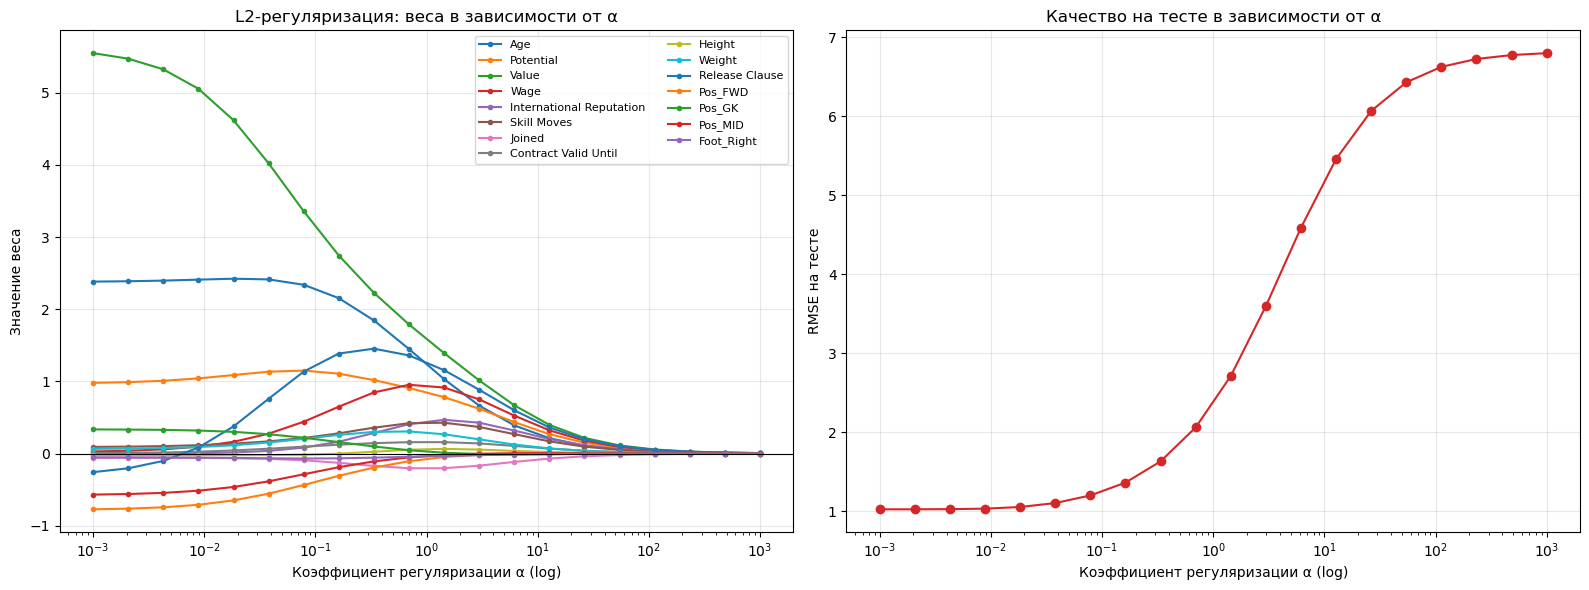

,Age,Potential,Value,Wage,International Reputation,Skill Moves,Joined,Contract Valid Until,Height,Weight,Release Clause,Pos_FWD,Pos_GK,Pos_MID,Foot_Right
α,,,,,,,,,,,,,,,
0.0010,2.383,0.980,5.551,0.029,-0.003,0.092,-0.058,0.006,-0.022,0.065,-0.258,-0.773,0.334,-0.569,-0.054
0.0089,2.411,1.041,5.057,0.095,0.005,0.115,-0.060,0.025,-0.023,0.090,0.082,-0.711,0.319,-0.515,-0.058
0.0785,2.339,1.149,3.359,0.441,0.082,0.215,-0.094,0.095,-0.016,0.203,1.136,-0.436,0.219,-0.288,-0.069
0.6952,1.449,0.909,1.790,0.953,0.407,0.420,-0.204,0.157,0.053,0.306,1.360,-0.106,0.046,-0.054,-0.045
6.1585,0.390,0.436,0.669,0.526,0.319,0.269,-0.116,0.106,0.036,0.125,0.599,-0.004,-0.011,0.004,-0.014
54.5559,0.055,0.078,0.112,0.092,0.059,0.050,-0.020,0.021,0.005,0.019,0.103,0.001,-0.003,0.002,-0.002
483.2930,0.006,0.009,0.013,0.011,0.007,0.006,-0.002,0.003,0.001,0.002,0.012,0.000,-0.000,0.000,-0.000


In [18]:
alphas = np.logspace(-3, 3, 20)          # 20 коэффициентов от 0.001 до 1000
L = np.linalg.eigvalsh(2 * Xtr.T @ Xtr / len(Xtr)).max()

W_path, b_path, n_steps = [], [], []
for alpha in alphas:
    # шаг подбираем под каждое alpha: ε = 1 / L, где L = λmax(Гессиана) = L + 2α, иначе GD разойдётся
    w_, b_, h_ = gradient_descent(Xtr, ytr, learning_rate=1 / (L + 2 * alpha),
                                  n_iter=20000, l2_lambda=alpha, eps=1e-10)
    W_path.append(w_); b_path.append(b_); n_steps.append(len(h_) - 1)
W_path = np.array(W_path)

# Проверка: сравниваем с аналитическим решением гребневой регрессии (b не штрафуется)
Xa = np.hstack([Xtr, np.ones((len(Xtr), 1))])
diffs = []
for alpha, w_ in zip(alphas, W_path):
    P = np.eye(Xa.shape[1]) * alpha; P[-1, -1] = 0
    sol = np.linalg.solve(Xa.T @ Xa / len(Xa) + P, Xa.T @ ytr / len(Xa))
    diffs.append(np.abs(sol[:-1] - w_).max())
print(f"Макс. отклонение весов GD от аналитического решения: {max(diffs):.2e}")

rmse_path = [test_rmse(w_, b_) for w_, b_ in zip(W_path, b_path)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for j, col in enumerate(X_train.columns):
    axes[0].plot(alphas, W_path[:, j], marker='o', ms=3, label=col)
axes[0].set_xscale('log')
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_xlabel('Коэффициент регуляризации α (log)')
axes[0].set_ylabel('Значение веса')
axes[0].set_title('L2-регуляризация: веса в зависимости от α')
axes[0].legend(fontsize=8, ncol=2, loc='upper right')
axes[0].grid(alpha=0.3)

axes[1].plot(alphas, rmse_path, marker='o', color='tab:red')
axes[1].set_xscale('log')
axes[1].set_xlabel('Коэффициент регуляризации α (log)')
axes[1].set_ylabel('RMSE на тесте')
axes[1].set_title('Качество на тесте в зависимости от α')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame(W_path, index=pd.Index(np.round(alphas, 4), name='α'), columns=X_train.columns).iloc[::3].round(3)

**Выводы по регуляризации**

- Спуск с подобранным шагом совпадает с аналитическим решением ridge с точностью около $7 \cdot 10^{-9}$, то есть реализация градиента и штрафа корректна.
- **С ростом $\alpha$ все веса сжимаются к нулю, но не обнуляются** (в отличие от L1). При $\alpha = 1000$ все веса порядка $10^{-3}$–$10^{-2}$.
- **Мультиколлинеарные признаки** `Value`, `Wage`, `Release Clause` при малых $\alpha$ ведут себя нестабильно: при $\alpha = 0.001$ вес `Release Clause` отрицательный (−0.26), а `Wage` почти нулевой (0.03) при весе `Value` 5.55. При росте $\alpha$ веса перераспределяются: `Value` падает до 3.4 при $\alpha \approx 0.08$, а `Wage` и `Release Clause` растут до 0.44 и 1.14. L2 «выравнивает» веса коррелированных признаков.
- Веса позиционных индикаторов (`Pos_FWD`, `Pos_MID`, `Pos_GK`) сжимаются быстрее всех и практически обнуляются уже при $\alpha \approx 6$; дольше всего сохраняют вес `Value`, `Release Clause`, `Wage`, `Potential` и `Age` (при $\alpha \approx 6$ это 0.4–0.7).
- **Качество на тесте с ростом $\alpha$ только ухудшается:** RMSE 1.023 при малых $\alpha$ и растёт до 6.80 при $\alpha = 1000$ — практически уровень константной модели (6.82). При 14 565 объектах и 15 признаках переобучения почти нет, поэтому регуляризация здесь не улучшает обобщение, а служит иллюстрацией и средством стабилизации весов коррелированных признаков. Приемлемым остаётся диапазон малых $\alpha$ (до $\approx 0.01$), где RMSE держится на уровне 1.02–1.03.